# 12 · 冠军核心：把协同过滤分数变成特征
## 目标
手算一个 ItemCF 相似度，核对原版代码，解释一条真实推荐。
“特征工程”在这里是可查看的数字：市场商品计数、评分统计、不同市场语料训练的模型分数。
## 准备
[可编辑实现](../reclab/competition/memory.py) · [冠军 icf_v2 原文件](../data/xmrec/upstream/winner/src/retrieval/icf_v2.py)。

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd()
if not (ROOT / "reclab").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code
from reclab.competition import data
from reclab.competition.teaching import load_run, style, bar_scores
style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 40)
run, rows, features = load_run()
print("实际训练快照:", run.name)

实际训练快照: 20261030T115556803593-cloud-restore


## 步骤 1 · 手算 IUF
二值历史矩阵 B，用户 u 的历史长度为 n_u：
`S_ij = sum_u[B_ui B_uj / log(1+n_u)] / sqrt(count_i count_j)`，令对角线为 0。
活跃用户连接很多商品，因此共现权重更小。用户候选分数为其历史商品到候选商品的相似度之和。

In [2]:
B = np.array([[1., 1., 0.], [0., 1., 1.], [1., 1., 1.]])
weights = 1 / np.log1p(B.sum(axis=1))
cooccur = B.T @ (weights[:, None] * B)
counts = B.sum(axis=0)
similarity = cooccur / np.sqrt(counts[:, None] * counts[None, :])
np.fill_diagonal(similarity, 0)
manual_01 = (1 / np.log(3) + 1 / np.log(4)) / np.sqrt(2 * 3)
assert np.isclose(similarity[0, 1], manual_01)
display(pd.DataFrame(similarity, index=["item A", "item B", "item C"], columns=["item A", "item B", "item C"]))
print("用户历史[A,B] -> C:", similarity[0, 2] + similarity[1, 2])

,item A,item B,item C
item A,0.000000,0.666093,0.360674
item B,0.666093,0.000000,0.666093
item C,0.360674,0.666093,0.000000


用户历史[A,B] -> C: 1.026766260457602


## 步骤 2 · 与固定版本的冠军代码数值对照
只提取经过校验的原类用于对照，不执行它的脚本入口、安装器或路径配置。
IUF 和 rating-cosine 是两种分数；原方案 rating-cosine 查询时也对历史做**无评分权重求和**。

In [3]:
from reclab.competition.reference import verify_references
parity = verify_references()
display(parity)
from reclab.competition.memory import ItemCF
display(Code(inspect.getsource(ItemCF.fit), language="python"))

lgn is already to go(dropout:False)


{'memory': {'iuf': {'max_score_error': 1.6360444821117426e-07, 'pairs': 384},
  'rating': {'max_score_error': 8.096896113585217e-07, 'pairs': 384}},
 'graph': {'loss_error': 0.0, 'gradient_max_error': 4.656612873077393e-10},
 'data': 't1 real training histories',
 'users': 8}

def fit(self, frame):
        self.users, self.items, ratings = encode(frame)
        binary = ratings.copy()
        binary.data[:] = 1
        self.history = binary
        values = ratings if self.kind == "rating" else binary
        if self.kind == "iuf":
            weight = 1 / np.log1p(np.diff(binary.indptr))
            weighted = values.multiply(weight[:, None]).tocsr()
        else:
            weighted = values
        sim = (values.T @ weighted).tocsr()
        norm = np.sqrt(np.asarray(values.power(2).sum(axis=0)).ravel())
        inv = 1 / np.maximum(norm, 1e-12)
        sim = sim.multiply(inv[:, None]).multiply(inv[None, :]).tocsr()
        sim.setdiag(0)
        sim.eliminate_zeros()
        if self.top_k:
            for row in range(sim.shape[0]):
                a, b = sim.indptr[row:row + 2]
                if b - a > self.top_k:
                    ids = np.lexsort((sim.indices[a:b], -sim.data[a:b]))[self.top_k:]
                    sim.data[a + ids] = 0
            sim.eliminate_zeros()
        self.similarity = sim
        self.popularity = np.asarray(binary.sum(axis=0)).ravel()
        return self

## 步骤 3 · 拆开真实候选分数
载入全数据实际训练产物，不重新训练现有模型。相似度贡献之和必须等于候选分数。
可以直接修改 `USER` 为同市场其他用户。

In [4]:
from reclab.competition.experiment import load_memory
model = load_memory(run / "memory/t1_local")
USER = rows.query("market == 't1'").userId.iloc[0]
subset = rows[(rows.market == "t1") & rows.userId.eq(USER)].copy()
subset["score"] = model.score(subset)
display(subset.sort_values("score", ascending=False).head(10))
ITEM = subset.sort_values(["score", "itemId"], ascending=[False, True]).itemId.iloc[0]
explanation = pd.DataFrame(model.explain(USER, ITEM))
display(explanation.head(10))
assert np.isclose(explanation.similarity.sum(), subset.loc[subset.itemId.eq(ITEM), "score"].iloc[0])

,userId,itemId,market,label,partition,score
80,t1U1005570,P1000949,t1,0,fit,0.091353
0,t1U1005570,P1005811,t1,0,fit,0.075901
73,t1U1005570,P1021121,t1,0,fit,0.069835
61,t1U1005570,P1033291,t1,0,fit,0.068454
57,t1U1005570,P1012526,t1,0,fit,0.050017
79,t1U1005570,P1008851,t1,0,fit,0.039970
56,t1U1005570,P1035707,t1,0,fit,0.036421
43,t1U1005570,P1021561,t1,0,fit,0.032723
71,t1U1005570,P1012765,t1,0,fit,0.032284
66,t1U1005570,P1029597,t1,0,fit,0.031917


,history_item,similarity
0,P1031263,0.068887
1,P1020517,0.012866
2,P1021106,0.006505
3,P1014278,0.003095
4,P1030052,0.000000


## 步骤 4 · 同一 user-item 到底有哪些特征
一行同时包含多个市场的商品计数、t1 自身统计和多个模型分数。ID 和 label 不进入排序特征。
没有真实属性表，这套竞赛复现不会假造类目或用户画像。

In [5]:
position = subset.index[0]
display(features.loc[position].rename("value").to_frame())
assert not {"label", "userId", "itemId", "partition"} & set(features)
table = pd.read_csv(run / "metrics.csv")
selected = table[(table.partition == "select") & (table.market.isin(["t1", "t2"])) & table.model.isin(["icf_local", "icf_s1", "icf_s3", "icf_all_iuf"])]
display(selected.pivot(index="model", columns="market", values="ndcg10"))

,value
s1_train_item_count,7.000000
s1_train_5core_item_count,0.000000
s2_train_item_count,7.000000
s2_train_5core_item_count,2.000000
s3_train_item_count,11.000000
s3_train_5core_item_count,2.000000
t1_train_item_count,19.000000
t1_train_5core_item_count,11.000000
target_user_rating_count,5.000000
target_user_rating_mean,4.800000


market,t1,t2
model,,
icf_all_iuf,0.684087,0.586053
icf_local,0.673879,0.562058
icf_s1,0.683179,0.582342
icf_s3,0.675800,0.565388


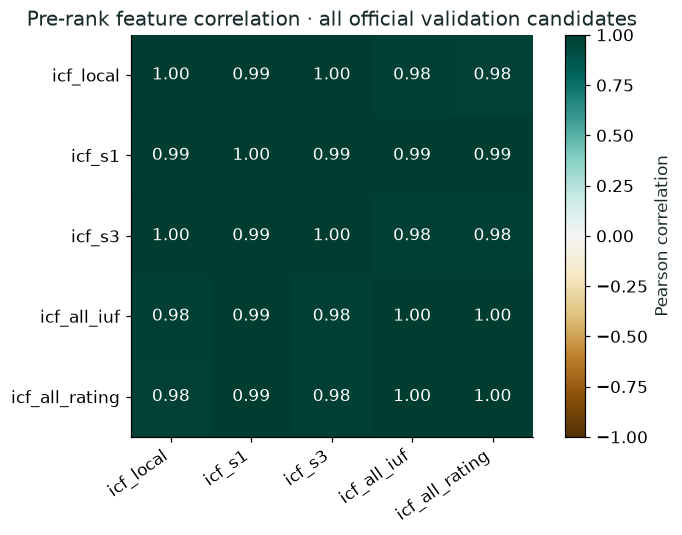

In [6]:
columns = ["icf_local", "icf_s1", "icf_s3", "icf_all_iuf", "icf_all_rating"]
correlation = features[columns].corr()
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="BrBG")
ax.set_xticks(range(len(columns)), columns, rotation=35, ha="right")
ax.set_yticks(range(len(columns)), columns)
for i in range(len(columns)):
    for j in range(len(columns)):
        ax.text(j, i, f"{correlation.iloc[i,j]:.2f}", ha="center", va="center", color="white" if abs(correlation.iloc[i,j]) > .65 else "black")
ax.set_title("Pre-rank feature correlation · all official validation candidates")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()

## 对照论文的实际分数

下面是无需目标验证标签训练的 ItemCF，在完整官方验证集上的结果。论文 Table 4 的数字是固定参考值，不与 LightGBM 的训练内分数混用。合并按用户数加权。本地有确定的 item-ID 同分规则，不能要求与原方案逐位相等。

In [7]:
full = table[(table.partition == "all_official_valid") & (table.model == "icf_local")][["market", "users", "ndcg10"]].copy()
full["paper_table4"] = full.market.map({"t1": .6776, "t2": .5589, "combined": .5980})
full["local_minus_paper"] = full.ndcg10 - full.paper_table4
display(full)
print("本地合并 nDCG@10:", round(float(full.loc[full.market.eq("combined"), "ndcg10"].iloc[0]), 6))

,market,users,ndcg10,paper_table4,local_minus_paper
15,t1,2697,0.677494,0.6776,-0.000106
16,t2,5482,0.558946,0.5589,0.000046
17,combined,8179,0.598037,0.5980,0.000037


本地合并 nDCG@10: 0.598037


## 检查与下一步
相关系数接近 1 的两个特征是否只能删掉一个？
<details><summary>答案路径</summary>不能仅凭相关性决定。先在 select 用户上做固定配置的消融；它们可能在某个市场或长尾用户上有互补信息。不要盯着 audit 反复挑特征。</details>
修改 `ItemCF.fit` 的权重、设置 `top_k` 都会改变分数，需要重新生成特征。进入 13 看可训练的表示。